In [2]:
import functools
import os

from ultralytics import YOLO
import pandas as pd

import ultralytics_validator_wrapper
from tflite_inference import TFLiteInferer

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
WEIGHTS_PTH = "results/filtered_v3_margin_15_yolo11/weights/best.pt"

BASE_PTH = "/home/klymy/data/people_detection/filtered_v3_margin_15"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")
ALGOTEST_PTH = os.path.join(BASE_PTH, "project_algotest.yaml")

CONF_TH = 0.25
IOU_TH = 0.55

args = dict(
    data=ALGOTEST_PTH,
    task="pose",
    device=[0],
    batch=128,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
    imgsz=320,
    model="val",
    rect=False,
    single_cls=False,
)

In [4]:
model = YOLO(WEIGHTS_PTH)

val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/algotest.cache... 9572 images, 559 backgrounds, 0 corrupt: 100%|██████████| 9572/9572 [00:00<?, ?it/s]
tst validation: 100%|██████████| 75/75 [01:08<00:00,  1.10it/s]


                   all       9572      51930      0.904      0.878      0.907      0.598      0.924       0.88      0.919      0.916
   task    F1     P     R  MAP@50
0   box 0.891 0.904 0.878   0.907
1  pose 0.901 0.924 0.880   0.919


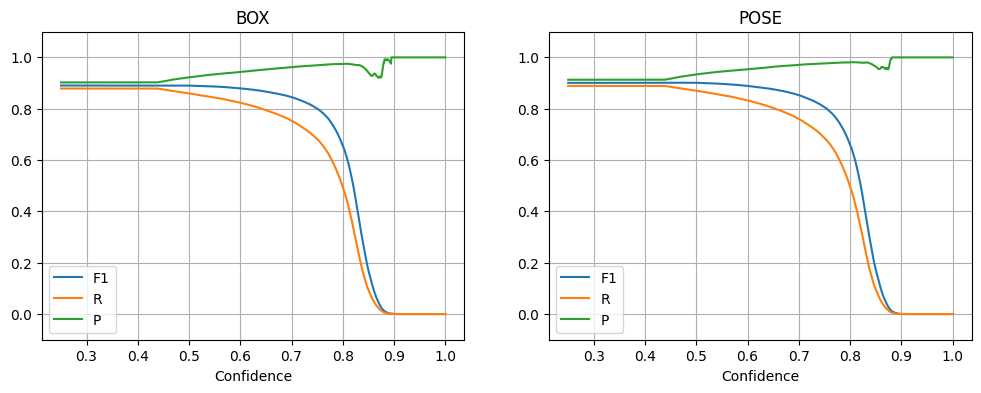

In [5]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_ultralytics, model, args),
)

In [6]:
inferer = TFLiteInferer(
    yolo_pth="results/filtered_v3_margin_15/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="results/filtered_v3_margin_15/weights/head_saved_model/head_float32.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/algotest.cache... 9572 images, 559 backgrounds, 0 corrupt: 100%|██████████| 9572/9572 [00:00<?, ?it/s]
tst validation: 100%|██████████| 75/75 [06:17<00:00,  5.03s/it]


                   all       9572      51930      0.903      0.861      0.901      0.593       0.92      0.878      0.919      0.915
   task    F1     P     R  MAP@50
0   box 0.882 0.903 0.861   0.901
1  pose 0.898 0.920 0.878   0.919


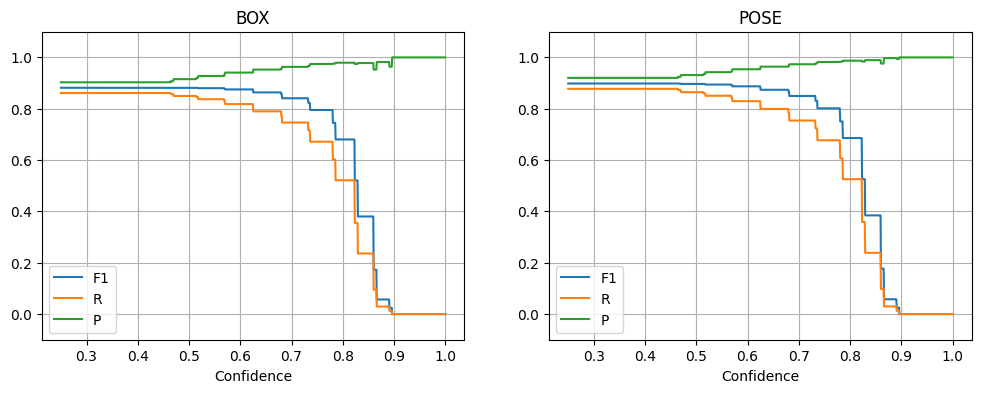

In [7]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args)
)

In [8]:
args["data"] = HOLDOUT_PTH

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_ultralytics, model, args),
    False,
)

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/holdout.cache... 22049 images, 556 backgrounds, 0 corrupt: 100%|██████████| 22049/22049 [00:00<?, ?it/s]
tst validation: 100%|██████████| 173/173 [02:39<00:00,  1.08it/s]


                   all      22049     114004      0.912      0.881      0.919      0.622      0.931        0.9      0.938      0.937
   task    F1     P     R  MAP@50
0   box 0.896 0.912 0.881   0.919
1  pose 0.916 0.931 0.900   0.938


val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/holdout.cache... 22049 images, 556 backgrounds, 0 corrupt: 100%|██████████| 22049/22049 [00:00<?, ?it/s]
tst validation: 100%|██████████| 173/173 [15:23<00:00,  5.34s/it]


                   all      22049     114004      0.919       0.87      0.912      0.617      0.941       0.89      0.933      0.931
   task    F1     P     R  MAP@50
0   box 0.894 0.919 0.870   0.912
1  pose 0.915 0.941 0.890   0.933
